# Analysis 8: Forecasting 30 days of views for US Music

**Business question.** How many views will trending Music videos in the US gain per day over the next 30 days? A label or a music platform could use this to plan release timing and promotion budgets.

**Series.** For each day, the sum of the view increases of all US Music videos on that day's list since their previous appearance. When a day is missing from the data, the increase is spread over the gap, and the 20 missing days are filled by linear interpolation. US Music was chosen because it has a clear weekly pattern and a long trend, and the US data has no structural break like India's.

**Method.** Five forecasters, from simple baselines to statistical models, are compared with rolling-origin evaluation: each is fitted on all data up to an origin date and scored on the next 30 days, at 10 origins 45 days apart. The last origin leaves the final 30 days of data (16 March to 15 April 2024) as the holdout. Scores are MAPE on daily values and the percent error of the 30-day total.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from streampulse.charts import SECONDARY_INK, apply_chart_style
from streampulse.database import connect
from streampulse.forecast import (
    FORECASTERS, HORIZON_DAYS, fit_sarima, load_daily_views_gained, mape, rolling_origin_evaluation, total_error,
)

MODEL_COLORS = {"SARIMA": "#6250d6", "4-week weekday average": "#eda100"}
ACTUAL_COLOR = "#0b0b0b"

apply_chart_style()
connection = connect()
views_gained = load_daily_views_gained(connection, "US", "Music")
print(f"{len(views_gained):,} days from {views_gained.index.min().date()} to {views_gained.index.max().date()}")

1,342 days from 2020-08-13 to 2024-04-15


## 1. The series

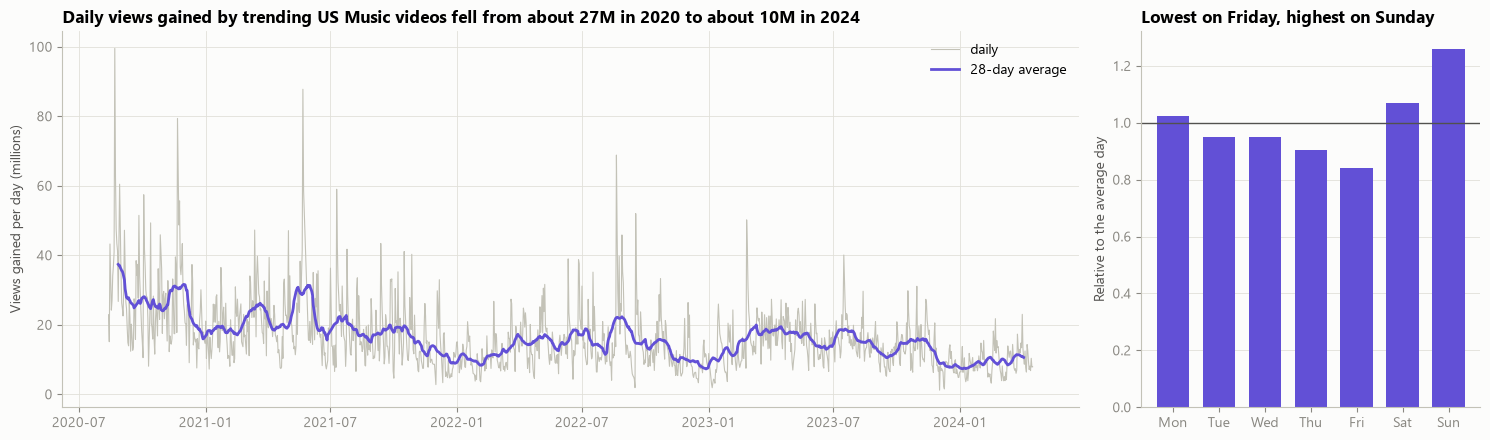

trending_date
2020    27.8
2021    19.0
2022    13.9
2023    14.5
2024     9.5
Name: mean views gained per day (millions), dtype: float64

In [2]:
fig, (series_ax, weekday_ax) = plt.subplots(1, 2, figsize=(15, 4.5), width_ratios=[3, 1])
series_ax.plot(views_gained.index, views_gained / 1e6, color="#c3c2b7", linewidth=0.8, label="daily")
series_ax.plot(views_gained.index, views_gained.rolling(28, center=True).mean() / 1e6, color="#6250d6",
               label="28-day average")
series_ax.set_ylabel("Views gained per day (millions)")
series_ax.set_title("Daily views gained by trending US Music videos fell from about 27M in 2020 to about 10M in 2024")
series_ax.legend()

weekday_profile = views_gained.groupby(views_gained.index.dayofweek).mean() / views_gained.mean()
weekday_ax.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], weekday_profile, color="#6250d6", width=0.7)
weekday_ax.axhline(1, color=SECONDARY_INK, linewidth=1)
weekday_ax.set_ylabel("Relative to the average day")
weekday_ax.set_title("Lowest on Friday, highest on Sunday")
weekday_ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

(views_gained.groupby(views_gained.index.year).mean() / 1e6).round(1).rename("mean views gained per day (millions)")

## 2. The forecasters

| Model | What it does |
|---|---|
| naive | repeats the last day |
| seasonal naive | repeats the last week |
| 4-week weekday average | each weekday's average over the last 4 weeks |
| Holt-Winters | exponential smoothing with a damped trend and weekly seasonality, on log views, all history |
| SARIMA | SARIMA(1,1,1)(0,1,1,7) on log views, last 365 days |

Models are fitted on log views because the series is skewed and its swings grow with its level; forecasts are converted back to views.

## 3. Rolling-origin evaluation

In [3]:
origin_positions = [len(views_gained) - HORIZON_DAYS - 1 - 45 * step for step in range(9, -1, -1)]
origins = views_gained.index[origin_positions]
evaluation = rolling_origin_evaluation(views_gained, origins)

evaluation.pivot(index="origin", columns="model", values="mape").rename(index=lambda origin: origin.date()).round(1)

model,4-week weekday average,Holt-Winters,SARIMA,naive,seasonal naive
origin,,,,,
2023-02-05,29.7,38.1,41.4,106.8,46.2
2023-03-22,29.6,20.9,20.6,19.9,18.1
2023-05-06,26.7,27.7,28.9,30.9,39.3
2023-06-20,32.1,31.1,31.0,28.2,32.8
2023-08-04,30.4,17.8,17.1,23.4,21.0
2023-09-18,26.3,31.2,29.3,26.7,39.9
2023-11-02,79.7,103.2,81.0,121.4,93.8
2023-12-17,39.5,68.5,33.9,108.5,53.7
2024-01-31,42.2,52.7,39.6,87.5,49.7


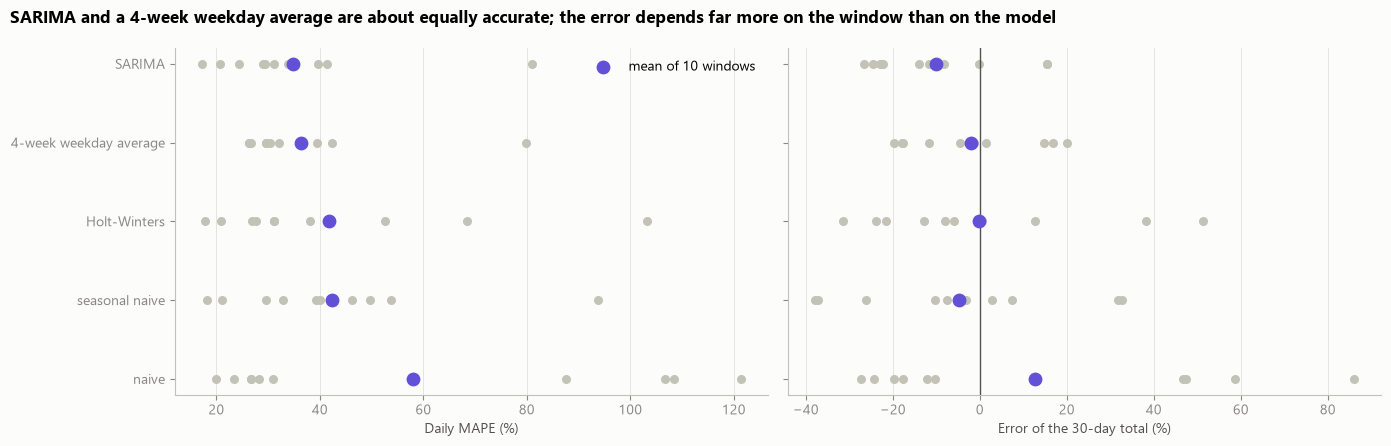

,mean_mape,median_mape,mean_abs_total_error,mean_total_error
model,,,,
SARIMA,34.7,30.2,16.2,-10.0
4-week weekday average,36.3,30.0,12.6,-2.0
Holt-Winters,41.8,31.1,20.7,-0.1
seasonal naive,42.4,39.6,19.7,-4.8
naive,58.0,29.6,35.0,12.7


In [4]:
model_summary = evaluation.assign(abs_total_error_pct=evaluation["total_error_pct"].abs()).groupby("model").agg(
    mean_mape=("mape", "mean"),
    median_mape=("mape", "median"),
    mean_abs_total_error=("abs_total_error_pct", "mean"),
    mean_total_error=("total_error_pct", "mean"),
).sort_values("mean_mape")

model_order = model_summary.index[::-1]
fig, (mape_ax, total_ax) = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, column, label in [(mape_ax, "mape", "Daily MAPE (%)"), (total_ax, "total_error_pct", "Error of the 30-day total (%)")]:
    for y_position, model in enumerate(model_order):
        fold_values = evaluation.loc[evaluation["model"] == model, column]
        ax.scatter(fold_values, np.full(len(fold_values), y_position), color="#c3c2b7", s=30, zorder=2)
        ax.scatter(fold_values.mean(), y_position, color="#6250d6", s=80, zorder=3,
                   label="mean of 10 windows" if y_position == 0 else None)
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
total_ax.axvline(0, color=SECONDARY_INK, linewidth=1)
mape_ax.set_yticks(range(len(model_order)), model_order)
mape_ax.legend(loc="upper right")
fig.suptitle("SARIMA and a 4-week weekday average are about equally accurate; the error depends far more on the window than on the model",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

model_summary.round(1)

## 4. The final holdout: 16 March to 15 April 2024

The shaded band is SARIMA's 80% prediction interval.

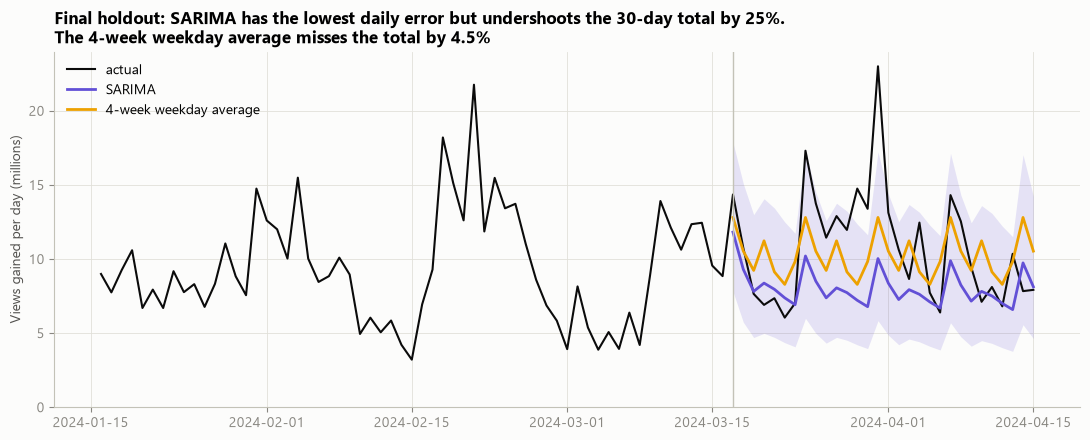

SARIMA 80% interval contains 90% of holdout days


,mape,total_error_pct
naive,26.8,-17.6
seasonal naive,29.5,7.3
4-week weekday average,26.3,-4.5
Holt-Winters,26.9,0.6
SARIMA,24.4,-24.7


In [5]:
holdout_origin = origins[-1]
train = views_gained.loc[:holdout_origin]
holdout = views_gained.loc[holdout_origin + pd.Timedelta(1, "D"):]
sarima_result = fit_sarima(train).get_forecast(HORIZON_DAYS)
sarima_interval = np.exp(sarima_result.conf_int(alpha=0.2))
holdout_forecasts = {name: forecaster(train) for name, forecaster in FORECASTERS.items()}

fig, ax = plt.subplots(figsize=(11, 4.5))
recent = views_gained.loc[holdout_origin - pd.Timedelta(60, "D"):]
ax.plot(recent.index, recent / 1e6, color=ACTUAL_COLOR, linewidth=1.5, label="actual")
ax.fill_between(holdout.index, sarima_interval.iloc[:, 0] / 1e6, sarima_interval.iloc[:, 1] / 1e6,
                color=MODEL_COLORS["SARIMA"], alpha=0.15, linewidth=0)
for name, color in MODEL_COLORS.items():
    ax.plot(holdout.index, holdout_forecasts[name] / 1e6, color=color, label=name)
ax.axvline(holdout.index[0], color="#c3c2b7", linewidth=1)
ax.set_ylim(0, None)
ax.set_ylabel("Views gained per day (millions)")
ax.set_title("Final holdout: SARIMA has the lowest daily error but undershoots the 30-day total by 25%.\n"
             "The 4-week weekday average misses the total by 4.5%")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

inside_interval = ((holdout.to_numpy() >= sarima_interval.iloc[:, 0].to_numpy())
                   & (holdout.to_numpy() <= sarima_interval.iloc[:, 1].to_numpy())).mean()
print(f"SARIMA 80% interval contains {100 * inside_interval:.0f}% of holdout days")
pd.DataFrame({
    name: {"mape": mape(holdout, predicted), "total_error_pct": total_error(holdout, predicted)}
    for name, predicted in holdout_forecasts.items()
}).T.round(1)

## 5. What broke the November 2023 window

Every model had its worst daily MAPE in the window starting 3 November 2023, yet that window's average was not unusual. MAPE divides each error by the actual value, so one day with a very small actual can dominate it.

In [6]:
worst_origin = evaluation.groupby("origin")["mape"].mean().idxmax()
worst_train = views_gained.loc[:worst_origin]
worst_window = views_gained.loc[worst_origin + pd.Timedelta(1, "D"): worst_origin + pd.Timedelta(HORIZON_DAYS, "D")]
lowest_day = worst_window.idxmin()
print(f"Window {worst_window.index[0].date()} to {worst_window.index[-1].date()}: mean {worst_window.mean() / 1e6:.1f}M a day, "
      f"lowest day {lowest_day.date()} with {worst_window.min() / 1e6:.2f}M (next lowest {worst_window.nsmallest(2).iloc[-1] / 1e6:.2f}M)")

without_lowest_day = worst_window.index != lowest_day
window_rows = {}
for name, forecaster in FORECASTERS.items():
    predicted = forecaster(worst_train)
    window_rows[name] = {
        "mape": mape(worst_window, predicted),
        "mape_without_lowest_day": mape(worst_window[without_lowest_day], predicted[without_lowest_day]),
        "total_error_pct": total_error(worst_window, predicted),
    }
pd.DataFrame(window_rows).T.round(1)

Window 2023-11-03 to 2023-12-02: mean 13.4M a day, lowest day 2023-12-02 with 1.19M (next lowest 6.28M)


,mape,mape_without_lowest_day,total_error_pct
naive,121.4,72.1,46.6
seasonal naive,93.8,63.6,31.7
4-week weekday average,79.7,51.2,14.7
Holt-Winters,103.2,63.5,38.3
SARIMA,81.0,46.6,15.5


## Finding

**A simple 4-week weekday average forecasts the monthly total about as well as SARIMA, and with less bias. Daily values stay hard to predict.**

- **Daily accuracy:** across 10 rolling 30-day windows, SARIMA has the lowest mean daily MAPE (34.7%, median 30.2%), closely followed by the 4-week weekday average (36.3%, median 30.0%). Holt-Winters (41.8%), the seasonal naive (42.4%) and the naive forecast (58.0%) are worse. The spread between windows (about 17% to 80% for the same model) is far larger than the spread between the two best models.
- **Monthly total:** the 4-week weekday average misses the 30-day total by 12.6% on average with almost no bias (-2.0%). SARIMA misses by 16.2% and under-forecasts by 10% on average. A likely reason is that it is fitted on log views: converting a log forecast back gives the median, which is below the mean for a skewed series like this one.
- **Final holdout (16 March to 15 April 2024):** SARIMA has the lowest daily MAPE (24.4%) but undershoots the total by 24.7%; the weekday average scores 26.3% daily and -4.5% on the total. SARIMA's 80% interval contained 90% of the holdout days, so its uncertainty band was, if anything, a little too wide.
- **Worst window (3 November to 2 December 2023):** daily MAPE reached 80% to 121%. One day, 2 December, had only 1.2M views gained against 6M to 27M on other days, and removing it cuts MAPE by 30 to 50 points. Even without it, this was the hardest window because daily values swung widely. Measured by the 30-day total, the two best models missed by about 15%.

**Business answer.** For planning a month ahead, the 4-week weekday average gives a total that is usually within about 13%, is easy to explain and is as good as a statistical model here. Day-level numbers should be treated as a range, because single big releases move them by 50% or more.

**Limitations**

- The series only counts views gained while videos are on the trending list, not all views of US Music.
- 20 missing days were interpolated, which smooths those points.
- MAPE is unstable when a day's actual value is small, so the 30-day total error is reported alongside it.
- One series and one horizon were tested; other categories, especially without a weekly pattern, may favour different models.